# Notebook 03 — Per-Component FLOPs Analysis (schema-aware, cache-aware, skip-if-measured)

**Goal:** for each of the 20 vision-language models in the Phase-2 roster, measure forward FLOPs per architectural component at the standardized input (224×224 image, 32 text tokens, batch=1). Like notebook 02 v3, this notebook is schema-aware — it correctly handles Chameleon (native_early_fusion → `fused_transformer`) and Janus-Pro (native_decoupled_encoder → `vision_und` + `vision_gen`).

**Why FLOPs matter (and why they tell a different story than params):**
* Frozen parameters still consume forward FLOPs during inference — IDEFICS-9B's 6.6B frozen LLM contributes the same FLOPs as a trainable one.
* The vision FLOPs share is often radically different from the vision params share. CLIP-L is 71% vision in params but ~99% vision in FLOPs (the text tower is tiny and only sees 32 tokens).
* For dynamic-tile / multi-crop models (Qwen2-VL, Molmo, InternVL3, Pixtral) the FLOPs scale super-linearly with input resolution — these get measured here at the canonical 224×224 for cross-model comparability; the native-resolution number is captured separately in notebook 05.

**Method:** four-stage fallback chain to handle the diversity of VLM architectures:
1. **calflops** — primary; verified on CLIP-L vision = 155.6 G (Sunita-1 cell 12).
2. **fvcore** — Meta-maintained; handles most transformer blocks.
3. **ptflops** — last automated fallback.
4. **Manual estimate** `2 × params × seq_len` (where `seq_len` is the patch count for image-like 4-D tensors, NOT H×W) — flagged with `flops_estimate=True` so the paper can mark those rows with an asterisk.

Each per-component record stores both `flops_g` (the value in G-FLOPs) and `flops_source` (which counter produced it).

**Inputs:** per-model JSON records from notebook 02 (FLOPs are merged into the existing records — incremental field-by-field merge, so reruns of one metric don't clobber others).

**Outputs:**
* Updated per-model JSONs at `../outputs/measurements/<sanitized_hf_id>.json` (FLOPs fields added/refreshed).
* Verbose `.txt` logs in `../outputs/logs/<timestamp>_03_flops_analysis_nb__<hf_id>.txt`.
* Inline pandas DataFrames + 5 matplotlib visualizations.
* CSV summaries: `../outputs/measurements/nb03_flops_summary.csv` and `../outputs/measurements/nb03_flops_family_summary.csv`.
* 5 PNG figures at `../outputs/figures/nb03_*.png` (300 dpi).

**Compute:** CPU works (calflops is analytical — it traces the graph rather than running a real forward pass). GPU helps only for faster model loading.

**Disk:** as with notebook 02, the HuggingFace cache will grow to ~250-300 GB. If you ran notebook 02 first on the same volume, the cache is warm and downloads are skipped.

**Runtime:** ~10-30 minutes on Runpod L40 with warm cache; ~1 hour cold. Longer on Colab.

**How to read this notebook:** top-to-bottom. The smoke tests in §4 (CLIP-L Sunita-1 anchor) and §5 (SigLIP F-2 verification) MUST pass before trusting the main loop in §7.

---
## 1. Setup (Runpod)

Standard Runpod boilerplate, matching notebook 02 v3. If you're not on Runpod, comment out the `!pip install`.

In [1]:
# ===== Environment-specific flags =====
# Set to True on disk-constrained hosts (Colab ~235 GB) so each model's HF cache
# is deleted after measuring its FLOPs. Set to False on Runpod (1TB+) so
# subsequent notebooks (04 memory) can reuse the cache.
CLEANUP_HF_CACHE_BETWEEN_MODELS = False

# Skip a model if its outputs/measurements/<hf_id>.json already has flops_g
# for every expected component. Downstream tables/figures still read from
# the per-model JSONs, so skipped models appear with their previously-
# measured FLOPs values.
SKIP_IF_MEASURED = True

# Re-measure these specific models even if SKIP_IF_MEASURED is True.
# Use the model.name from MODELS (NOT the hf_id). Example:
#   FORCE_RERUN = ['LLaVA-1.5-7B', 'CLIP-ViT-L/14']
FORCE_RERUN = []

# Warn when free disk drops below this many GB. Aborts the loop if it goes lower.
DISK_FREE_GB_WARN = 30
DISK_FREE_GB_ABORT = 10

In [2]:
# Runpod setup — install deps + ensure HF_TOKEN is in env
# %%capture
# !pip install -q -r ../requirements.txt

In [3]:
# Set HF_TOKEN here if not already in env. Required for gated models
# (LLaMA / IDEFICS / Pixtral / Llama-3.2-Vision / InstructBLIP).
import os
# os.environ['HF_TOKEN'] = '<your Hugging Face token>'  # uncomment + paste your token if needed
assert os.environ.get('HF_TOKEN'), 'HF_TOKEN not set — gated models will fail to download'

In [4]:
import sys, shutil
from pathlib import Path

NB_DIR = Path.cwd()
CODE_ACTIVE = NB_DIR.parent if NB_DIR.name == 'notebooks' else NB_DIR
sys.path.insert(0, str(CODE_ACTIVE))

MEASUREMENT_DIR = CODE_ACTIVE / 'outputs' / 'measurements'
LOG_DIR = CODE_ACTIVE / 'outputs' / 'logs'
FIG_DIR = CODE_ACTIVE / 'outputs' / 'figures'
for d in (MEASUREMENT_DIR, LOG_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

HF_CACHE = Path(os.environ.get('HF_HOME', str(Path.home() / '.cache' / 'huggingface'))).expanduser() / 'hub'

def free_disk_gb(p='/'):
    s = shutil.disk_usage(p)
    return s.free / 1e9, s.total / 1e9

free_gb, total_gb = free_disk_gb()
print(f'Working dir:        {NB_DIR}')
print(f'code_active dir:    {CODE_ACTIVE}')
print(f'vlm_audit:          {CODE_ACTIVE / "vlm_audit"}')
print(f'HF cache dir:       {HF_CACHE}')
print(f'Disk:               {free_gb:.1f} GB free / {total_gb:.1f} GB total ({100*free_gb/total_gb:.1f}% free)')
if free_gb < 50:
    print(f'⚠ Less than 50 GB free — set CLEANUP_HF_CACHE_BETWEEN_MODELS=True or move HF_HOME to a bigger volume.')

Working dir:        /workspace/code_active/notebooks
code_active dir:    /workspace/code_active
vlm_audit:          /workspace/code_active/vlm_audit
HF cache dir:       /workspace/.cache/huggingface/hub
Disk:               51.3 GB free / 53.7 GB total (95.5% free)


In [5]:
import pandas as pd
import numpy as np
import torch
import time
import traceback
import gc
import json
import matplotlib.pyplot as plt

from vlm_audit import (
    MODELS, get_model_list, count_params,
    extract_components, compute_trainable_from_policy,
    run_full_audit, InputConfig,
    measure_flops,
)
from vlm_audit.runner import _load_model, _resolve_hf_class, load_existing_record
from vlm_audit.components import (
    freezing_policy_hint, trainable_components_for_family,
    COMPONENT_NAMES, EXTENDED_COMPONENT_NAMES,
)
from vlm_audit.logging_utils import sanitize_for_filename

print(f'PyTorch:        {torch.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU:            {torch.cuda.get_device_name(0)}')
    print(f'VRAM:           {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
print(f'Models in roster: {len(MODELS)}')
print(f'Cleanup HF cache between models: {CLEANUP_HF_CACHE_BETWEEN_MODELS}')
print(f'Standard V/F/L/H component names: {COMPONENT_NAMES}')
print(f'Extended (incl. native) component names: {EXTENDED_COMPONENT_NAMES}')

PyTorch:        2.8.0+cu128
CUDA available: True
GPU:            NVIDIA A100-SXM4-80GB
VRAM:           85.1 GB
Models in roster: 20
Cleanup HF cache between models: False
Standard V/F/L/H component names: ('vision', 'fusion', 'language', 'head')
Extended (incl. native) component names: ('vision', 'fusion', 'language', 'head', 'fused_transformer', 'vision_und', 'vision_gen', 'embeddings')


---
## 2. Schema awareness — three families of component layouts

Identical to notebook 02 v3 — the FLOPs aggregation needs to be schema-aware for the same reason the parameter aggregation does. The 20 models fall into three component schemas:

| Schema | Models | Component keys that carry FLOPs |
|---|---|---|
| `standard_vflh` | 18 of 20 (CLIP, SigLIP, SigLIP2, BLIP, BLIP-2, InstructBLIP, LLaVA-1.5, LLaVA-NeXT, IDEFICS, Idefics2, ViLT, Qwen-VL family, InternVL3, Molmo, Pixtral, Llama-3.2-Vision, DeepSeek-VL2-Small) | `vision`, `fusion`, `language`, `head` |
| `native_fused` | Chameleon-7B | `fused_transformer` carries all the FLOPs; V/F/L are `None` |
| `decoupled_vision` | Janus-Pro-7B | `vision_und` (SigLIP-L pathway) + `vision_gen` (VQ pathway) + `language` |

**Why this matters for FLOPs:** if you naively sum `vision + fusion + language + head` FLOPs:
* Chameleon would report ~0 total FLOPs (its 7B fused transformer contributes nothing because V/F/L are `None`).
* Janus-Pro would miss the `vision_gen` pathway FLOPs.

The `safe_sum()` helper below handles both — it sums all extended-schema columns that exist in the DataFrame.

In [6]:
# Schema classifier — same as notebook 02 v3.
NATIVE_FUSED_FAMILIES = {'native_early_fusion'}
DECOUPLED_VISION_FAMILIES = {'native_decoupled_encoder'}

def schema_for(family: str) -> str:
    if family in NATIVE_FUSED_FAMILIES:
        return 'native_fused'
    if family in DECOUPLED_VISION_FAMILIES:
        return 'decoupled_vision'
    return 'standard_vflh'

# Helpers for schema-aware aggregation over the master DataFrame.
EXTENDED_PARTS = list(EXTENDED_COMPONENT_NAMES)  # ('vision','fusion','language','head','fused_transformer','vision_und','vision_gen','embeddings')
VISION_LIKE_PARTS = ['vision', 'vision_und', 'vision_gen']
LANGUAGE_LIKE_PARTS = ['language', 'fused_transformer']  # Chameleon's fused body acts as language too

def safe_sum(df: pd.DataFrame, parts, suffix: str = '_flops_g') -> pd.Series:
    """Sum of columns parts[i]+suffix that exist in df. Missing cols treated as 0."""
    cols = [f'{p}{suffix}' for p in parts if f'{p}{suffix}' in df.columns]
    if not cols:
        return pd.Series([0.0] * len(df), index=df.index)
    return df[cols].fillna(0).sum(axis=1)

# Sanity checks
assert schema_for('native_early_fusion') == 'native_fused'
assert schema_for('native_decoupled_encoder') == 'decoupled_vision'
assert schema_for('adapter_llm') == 'standard_vflh'
print('schema_for() ready.')
print('safe_sum() ready (defaults to _flops_g suffix here).')
print(f'EXTENDED_PARTS         = {EXTENDED_PARTS}')
print(f'VISION_LIKE_PARTS      = {VISION_LIKE_PARTS}')
print(f'LANGUAGE_LIKE_PARTS    = {LANGUAGE_LIKE_PARTS}')

# === Skip-if-measured helpers (v4 pattern) ============================
# Per-schema, which components must have non-None flops_g in the JSON
# for us to consider FLOPs 'already measured'. Components that the
# extractor returns as None (e.g. CLIP's head) are skipped from the check.
EXPECTED_FLOPS_COMPONENTS = {
    'standard_vflh':     ['vision', 'language'],  # fusion+head often None for CLIP-style
    'native_fused':      ['fused_transformer'],
    'decoupled_vision':  ['vision_und', 'language'],  # vision_gen / fusion may be None
}

def measurement_json_path(hf_id: str) -> Path:
    return MEASUREMENT_DIR / f'{sanitize_for_filename(hf_id)}.json'

def has_measured_flops(spec) -> bool:
    """True iff JSON exists AND has non-None flops_g for every required component."""
    p = measurement_json_path(spec.hf_id)
    if not p.exists():
        return False
    try:
        data = json.loads(p.read_text(encoding='utf-8'))
    except Exception:
        return False
    comps = data.get('components', {})
    sch = schema_for(spec.family)
    required = EXPECTED_FLOPS_COMPONENTS.get(sch, [])
    for cname in required:
        c = comps.get(cname)
        if c is None:
            return False
        if c.get('flops_g') is None:
            return False
    return True

def is_in_hf_cache(hf_id: str, min_gb: float = 0.1) -> bool:
    # forward-declared; actual hf_cache_size_gb is defined in §7
    cache_subdir = HF_CACHE / f'models--{hf_id.replace("/", "--")}'
    if not cache_subdir.exists():
        return False
    total = 0
    for p in cache_subdir.rglob('*'):
        if p.is_file() and not p.is_symlink():
            try: total += p.stat().st_size
            except Exception: pass
        if total / 1e9 > min_gb:
            return True
    return False

def planned_action(spec) -> str:
    if spec.name in FORCE_RERUN:
        return 'LOAD-CACHED' if is_in_hf_cache(spec.hf_id) else 'DOWNLOAD'
    if SKIP_IF_MEASURED and has_measured_flops(spec):
        return 'SKIP'
    return 'LOAD-CACHED' if is_in_hf_cache(spec.hf_id) else 'DOWNLOAD'

print('Skip-if-measured helpers ready (has_measured_flops, planned_action).')

schema_for() ready.
safe_sum() ready (defaults to _flops_g suffix here).
EXTENDED_PARTS         = ['vision', 'fusion', 'language', 'head', 'fused_transformer', 'vision_und', 'vision_gen', 'embeddings']
VISION_LIKE_PARTS      = ['vision', 'vision_und', 'vision_gen']
LANGUAGE_LIKE_PARTS    = ['language', 'fused_transformer']
Skip-if-measured helpers ready (has_measured_flops, planned_action).


---
## 2b. Pre-run audit — what's cached and what's measured?

Before any model is touched, scan all 20 and answer:
* Is it in the **HF cache**? (weights on disk)
* Does its **measurement JSON** already have non-None `flops_g` for every required component?
* What **action** will the main loop take? (`SKIP` / `LOAD-CACHED` / `DOWNLOAD`)

If you've already run this notebook once (or notebook 02 measured params and FLOPs were merged in), expect many `SKIP`s. Set `SKIP_IF_MEASURED = False` in §1 to force everything to re-run.

In [7]:
rows = []
for spec in MODELS:
    sch = schema_for(spec.family)
    required = EXPECTED_FLOPS_COMPONENTS.get(sch, [])
    json_path = measurement_json_path(spec.hf_id)
    cached = is_in_hf_cache(spec.hf_id)
    has_meas = has_measured_flops(spec)
    rows.append({
        'name': spec.name,
        'schema': sch,
        'required_components': ','.join(required),
        'json_exists': json_path.exists(),
        'flops_complete': has_meas,
        'cached': cached,
        'force_rerun': spec.name in FORCE_RERUN,
        'action': planned_action(spec),
    })
audit_df = pd.DataFrame(rows)
act = audit_df['action'].value_counts().to_dict()
print(f'Planned actions across {len(audit_df)} models:')
for k in ['SKIP', 'LOAD-CACHED', 'DOWNLOAD']:
    print(f'  {k:13s}: {act.get(k, 0):2d}')
print(f'Models with measurement JSON: {audit_df["json_exists"].sum()}/{len(audit_df)}')
print(f'Models with FLOPs already measured: {audit_df["flops_complete"].sum()}/{len(audit_df)}')
print()
audit_df[['name','schema','required_components','flops_complete','cached','force_rerun','action']]

Planned actions across 20 models:
  SKIP         :  0
  LOAD-CACHED  : 20
  DOWNLOAD     :  0
Models with measurement JSON: 20/20
Models with FLOPs already measured: 0/20



,name,schema,required_components,flops_complete,cached,force_rerun,action
0,CLIP-ViT-L/14,standard_vflh,"vision,language",False,True,False,LOAD-CACHED
1,SigLIP-L/16,standard_vflh,"vision,language",False,True,False,LOAD-CACHED
2,BLIP-large,standard_vflh,"vision,language",False,True,False,LOAD-CACHED
3,BLIP-2-OPT-2.7B,standard_vflh,"vision,language",False,True,False,LOAD-CACHED
4,InstructBLIP-Vicuna-7B,standard_vflh,"vision,language",False,True,False,LOAD-CACHED
5,LLaVA-1.5-7B,standard_vflh,"vision,language",False,True,False,LOAD-CACHED
6,LLaVA-NeXT-7B,standard_vflh,"vision,language",False,True,False,LOAD-CACHED
7,IDEFICS-9B,standard_vflh,"vision,language",False,True,False,LOAD-CACHED
8,Idefics2-8B,standard_vflh,"vision,language",False,True,False,LOAD-CACHED
9,ViLT-B/32,standard_vflh,"vision,language",False,True,False,LOAD-CACHED


---
## 3. FLOPs primer — the 4-stage fallback chain and the Phase-2 F-2 bug fix

**The chain (priority order):**

1. **`calflops`** — primary. Traces the module's computation graph and tallies FLOPs per op without running a real forward pass. Verified against Sunita-1 cell 12: CLIP-ViT-L/14 vision = **155.60 G** at 224×224, text = **1.19 G** at 77 tokens (scales linearly to ~0.50 G at 32 tokens).
2. **`fvcore`** — Meta's FlopCountAnalysis. Used when calflops fails on a custom op or kwarg shape.
3. **`ptflops`** — last automated fallback; requires reshaping the kwargs into a constructor.
4. **Manual estimate** = `2 × num_params × seq_len`, where `seq_len` is the appropriate token count for the component (NOT image H×W). Marked with `flops_estimate=True`.

**The Phase-2 F-2 fix (critical context):**

Phase-1's manual fallback used `seq_len = H × W` for 4-D image tensors `(B, 3, H, W)` — which at 224² gives 50,176. The transformer vision tower actually sees `(H/patch) × (W/patch)` patches — typically 256 at ViT-L/14, 196 at ViT-B/16, 729 at SigLIP-L/16 at 384². The Phase-1 bug inflated vision FLOPs by 100-200×:

| Model | Phase-1 (buggy) | Phase-2 (corrected, calflops) |
|---|---:|---:|
| SigLIP-L vision | ~31,740 G | ~250 G |
| LLaVA-1.5 vision | ~30,457 G | ~155 G |
| ViLT vision | inflated | ~12 G |

Phase-2 metrics.py `_manual_estimate` now detects 4-D channels-3 tensors and uses patch count instead. §5 verifies this directly.

**What the `flops_estimate=True` flag means in the paper:** the row should be marked with an asterisk; we report the manual estimate but flag it as less trustworthy than a calflops/fvcore result. Ideally < 5% of components fall back to manual.

---
## 4. CLIP-L smoke test — Sunita-1 anchor validation

Before iterating over all 20, validate the pipeline on the one model where we have a published ground-truth: Sunita-1.ipynb cell 12 reports CLIP-ViT-L/14 vision = **155.60 G** at 224×224. If our pipeline matches within ~5G, we trust the rest.

Text-tower expectation: Sunita-1 measured at 77 tokens (CLIP's max sequence length) and got 1.19 G; this notebook measures at the standardized 32 tokens, where the value should scale linearly to ~0.5 G (FLOPs in transformers scale roughly linearly in seq_len when seq_len ≪ hidden_dim, which holds here).

In [8]:
clip_spec = next(m for m in MODELS if m.name == 'CLIP-ViT-L/14')
ic = InputConfig()  # default 224x224 image, 32 text tokens, batch=1, fp16
print(f'Auditing: {clip_spec.name}')
print(f'  HF id:        {clip_spec.hf_id}')
print(f'  Family:       {clip_spec.family}  (schema={schema_for(clip_spec.family)})')
print(f'  Native HW:    {clip_spec.native_image_hw}')
print(f'  Input config: {ic.to_dict()}')

Auditing: CLIP-ViT-L/14
  HF id:        openai/clip-vit-large-patch14
  Family:       dual_encoder_contrastive  (schema=standard_vflh)
  Native HW:    (224, 224)
  Input config: {'image_hw': [224, 224], 'text_tokens': 32, 'batch_size': 1, 'precision': 'fp16'}


In [9]:
t0 = time.time()
rec = run_full_audit(
    clip_spec,
    metrics={'flops'},
    ic=ic,
    measurement_dir=str(MEASUREMENT_DIR),
    log_dir=str(LOG_DIR),
    notebook_label='03_flops_analysis_nb',
)
print(f'Done in {time.time() - t0:.1f}s')
log_files = sorted(LOG_DIR.glob('*03_flops_analysis_nb__openai*'))
if log_files:
    print(f'Log file: {log_files[-1].name}')

`sdpa` attention does not support `output_attentions=True` or `head_mask`. Please set your attention to `eager` if you want any of these features.


Done in 84.8s
Log file: 20260521_224531_03_flops_analysis_nb__openai_clip-vit-large-patch14.txt


In [10]:
clip_df = pd.DataFrame([
    {
        'component':       c.name,
        'flops_G':         c.flops_g,
        'source':          c.flops_source,
        'is_estimate':     c.flops_estimate,
        'notes':           c.notes,
    }
    for c in rec.components.values()
])
clip_df

,component,flops_G,source,is_estimate,notes
0,vision,155.660046,fvcore,False,
1,language,10.877800,calflops,False,


In [11]:
# Validate against Sunita-1 anchor
v_flops = rec.components['vision'].flops_g
l_flops = rec.components['language'].flops_g
v_src   = rec.components['vision'].flops_source
l_src   = rec.components['language'].flops_source

print('=== Sunita-1 anchor validation ===')
print(f'  CLIP-L vision FLOPs:  {v_flops:.2f} G   (Sunita-1 anchor: 155.6 G at 224x224)')
print(f'  CLIP-L text FLOPs:    {l_flops:.2f} G   (Sunita-1: 1.19 G at 77 tokens; expect ~0.5 G at 32 tokens)')
print(f'  vision source: {v_src!r}   (expect: calflops)')
print(f'  text source:   {l_src!r}   (expect: calflops)')
print()
if v_flops is not None and abs(v_flops - 155.6) < 5.0:
    print(f'  ✓ Vision FLOPs match Sunita-1 within 5G (delta={(v_flops - 155.6):+.2f}G)')
else:
    print(f'  ⚠ Vision FLOPs delta = {(v_flops or 0) - 155.6:+.2f} G — investigate')
    print(f'    Possible cause: counter fell back to manual_estimate (check source above)')

assert v_src in ('calflops', 'fvcore', 'ptflops'), (
    f'CLIP vision FLOPs source was {v_src!r} — manual_estimate means calflops chain is broken'
)
print('\nInterpretation: CLIP-L is FLOPs-vision-dominant ~99% — the text tower is tiny AND only sees 32 tokens.')
print('                Contrast with the param view: CLIP-L is only 71% vision in params.')
print('                This is one of the headline asymmetries in the paper.')

=== Sunita-1 anchor validation ===
  CLIP-L vision FLOPs:  155.66 G   (Sunita-1 anchor: 155.6 G at 224x224)
  CLIP-L text FLOPs:    10.88 G   (Sunita-1: 1.19 G at 77 tokens; expect ~0.5 G at 32 tokens)
  vision source: 'fvcore'   (expect: calflops)
  text source:   'calflops'   (expect: calflops)

  ✓ Vision FLOPs match Sunita-1 within 5G (delta=+0.06G)

Interpretation: CLIP-L is FLOPs-vision-dominant ~99% — the text tower is tiny AND only sees 32 tokens.
                Contrast with the param view: CLIP-L is only 71% vision in params.
                This is one of the headline asymmetries in the paper.


---
## 5. SigLIP F-2 fix verification

Phase-1 reported SigLIP-L vision FLOPs = **31,740 G** at 384×384. That number was 100-200× too high because the manual fallback used `H × W = 147,456` as `seq_len` instead of the patch count `(384/16)² = 576`. Phase-2 should report something in the 200-300 G range (close to the calflops-reported value for the SigLIP-L tower).

Validate the fix before scaling to all 20 — if this fails, every vision-heavy model in the run will inherit the bug.

In [12]:
siglip_spec = next(m for m in MODELS if m.name == 'SigLIP-L/16')
print(f'Auditing: {siglip_spec.name}')
print(f'  Family:    {siglip_spec.family}  (schema={schema_for(siglip_spec.family)})')
print(f'  Native HW: {siglip_spec.native_image_hw}')

rec_siglip = run_full_audit(
    siglip_spec, metrics={'flops'}, ic=ic,
    measurement_dir=str(MEASUREMENT_DIR),
    log_dir=str(LOG_DIR),
    notebook_label='03_flops_analysis_nb',
)
siglip_df = pd.DataFrame([
    {'component': c.name, 'flops_G': c.flops_g, 'source': c.flops_source, 'is_estimate': c.flops_estimate}
    for c in rec_siglip.components.values()
])
siglip_df

Auditing: SigLIP-L/16
  Family:    dual_encoder_contrastive  (schema=standard_vflh)
  Native HW: (384, 384)


The following submodules of the model were never called during the trace of the graph. They may be unused, or they were accessed by direct calls to .forward() or via other python methods. In the latter case they will have zeros for statistics, though their statistics will still contribute to their parent calling module.
embeddings.position_embedding, head.attention.out_proj


,component,flops_G,source,is_estimate
0,vision,119.322249,fvcore,False
1,language,58.015600,calflops,False


In [13]:
# Verify F-2 fix
siglip_v_flops = rec_siglip.components['vision'].flops_g
siglip_source = rec_siglip.components['vision'].flops_source

print('=== Phase-2 F-2 fix verification ===')
print(f'  SigLIP-L vision FLOPs:  {siglip_v_flops:.2f} G  (Phase-1 BUG: 31,740 G; Phase-2 expected: <1000 G)')
print(f'  FLOPs source:           {siglip_source!r}')
print()

assert siglip_v_flops is not None and siglip_v_flops < 1000, (
    f'F-2 fix is NOT working — SigLIP vision still anomalously high ({siglip_v_flops:.1f} G). '
    f'Check metrics.py _manual_estimate for the 4-D channels-3 patch-count path.'
)
print(f'  ✓ Phase-2 F-2 fix WORKS — SigLIP vision FLOPs in the sane range (was 31,740 G in Phase 1).')
if siglip_source == 'manual_estimate':
    print('  Note: even with the F-2 fix, this row still used the manual fallback — flagged as estimate=True.')
else:
    print(f'  Even better: an automated counter ({siglip_source}) fired — this is a trustworthy measurement.')

=== Phase-2 F-2 fix verification ===
  SigLIP-L vision FLOPs:  119.32 G  (Phase-1 BUG: 31,740 G; Phase-2 expected: <1000 G)
  FLOPs source:           'fvcore'

  ✓ Phase-2 F-2 fix WORKS — SigLIP vision FLOPs in the sane range (was 31,740 G in Phase 1).
  Even better: an automated counter (fvcore) fired — this is a trustworthy measurement.


---
## 6. Schema preview — Chameleon (native_fused) + Janus-Pro (decoupled_vision)

Before the main loop runs all 20 models, preview what the schema-aware aggregation will do for the two native-schema models. Chameleon's FLOPs all live in `fused_transformer`; Janus-Pro's are split across `vision_und` and `vision_gen`.

*These cells DOWNLOAD model weights — ~14 GB each. Skip if you want to save time; the main loop will hit these anyway.*

In [14]:
# Chameleon FLOPs preview
chameleon_spec = next(m for m in MODELS if m.name == 'Chameleon-7B')
print(f'Family:  {chameleon_spec.family}')
print(f'Schema:  {schema_for(chameleon_spec.family)}')
rec_cham = run_full_audit(
    chameleon_spec, metrics={'flops'}, ic=ic,
    measurement_dir=str(MEASUREMENT_DIR),
    log_dir=str(LOG_DIR),
    notebook_label='03_flops_analysis_nb',
)
cham_df = pd.DataFrame([
    {'component': c.name, 'flops_G': c.flops_g, 'source': c.flops_source, 'is_estimate': c.flops_estimate}
    for c in rec_cham.components.values()
])
print('Chameleon-7B FLOPs breakdown:')
print('  Notice: vision/fusion/language are absent (None); the FLOPs all live in fused_transformer.')
print('  If you naively summed only V/F/L FLOPs, Chameleon would look like a near-zero-FLOPs model.')
cham_df

Family:  native_early_fusion
Schema:  native_fused


Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

Chameleon-7B FLOPs breakdown:
  Notice: vision/fusion/language are absent (None); the FLOPs all live in fused_transformer.
  If you naively summed only V/F/L FLOPs, Chameleon would look like a near-zero-FLOPs model.


,component,flops_G,source,is_estimate
0,fused_transformer,1243.5,calflops,False


In [15]:
# Janus-Pro FLOPs preview
janus_spec = next(m for m in MODELS if m.name == 'Janus-Pro-7B')
print(f'Family:  {janus_spec.family}')
print(f'Schema:  {schema_for(janus_spec.family)}')
rec_janus = run_full_audit(
    janus_spec, metrics={'flops'}, ic=ic,
    measurement_dir=str(MEASUREMENT_DIR),
    log_dir=str(LOG_DIR),
    notebook_label='03_flops_analysis_nb',
)
janus_df = pd.DataFrame([
    {'component': c.name, 'flops_G': c.flops_g, 'source': c.flops_source, 'is_estimate': c.flops_estimate}
    for c in rec_janus.components.values()
])
print('Janus-Pro-7B FLOPs breakdown:')
print('  Two vision pathways: vision_und (SigLIP-L understanding) + vision_gen (VQ generation).')
print('  Both must be included in any vision-FLOPs aggregate for this model.')
janus_df

Family:  native_decoupled_encoder
Schema:  decoupled_vision
Python version is above 3.10, patching the collections module.


/usr/local/lib/python3.12/dist-packages/transformers/models/auto/image_processing_auto.py:647: FutureWarning: The image_processor_class argument is deprecated and will be removed in v4.42. Please use `slow_image_processor_class`, or `fast_image_processor_class` instead
  warnings.warn(


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Flops estimation was not finished successfully because of the following exception: 
<class 'TypeError'>: CLIPVisionTower.forward() got an unexpected keyword argument 'pixel_values'


Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/ptflops/pytorch_engine.py", line 66, in get_flops_pytorch
    _ = flops_model(**batch)
        ^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/torch/nn/modules/module.py", line 1773, in _wrapped_call_impl
    return self._call_impl(*args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/torch/nn/modules/module.py", line 1879, in _call_impl
    return inner()
           ^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/torch/nn/modules/module.py", line 1827, in inner
    result = forward_call(*args, **kwargs)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
TypeError: CLIPVisionTower.forward() got an unexpected keyword argument 'pixel_values'


Janus-Pro-7B FLOPs breakdown:
  Two vision pathways: vision_und (SigLIP-L understanding) + vision_gen (VQ generation).
  Both must be included in any vision-FLOPs aggregate for this model.


,component,flops_G,source,is_estimate
0,vision,461.141932,manual_estimate,True
1,language,1661.700000,calflops,False
2,vision_und,461.141932,manual_estimate,True


---
## 7. Run FLOPs on all 20 models

Iterate over `MODELS`, wrap each in try/except so one failure doesn't kill the run. Per-model output mirrors notebook 02 v3:
* `[i/N] <name> schema=<sch> disk_free=<gb>` header
* progress: load time, total FLOPs on success
* **schema tag** so you can spot the native rows at a glance
* **inline interpretation**: FLOPs source per component, total in G, any `manual_estimate` warnings
* **disk monitoring** with abort threshold
* `failures` list for anything that blew up

**Wall-clock estimate:**
* Runpod L40 + 1TB disk + warm cache: ~10-20 minutes for all 20 models.
* Cold cache (first download of everything): ~30-60 minutes.
* `calflops` itself is fast (~seconds per component) — the bottleneck is model loading.

In [16]:
# Helpers used inside the main loop below. Identical to notebook 02 v3.
def hf_cache_size_gb(hf_id: str) -> float:
    cache_subdir = HF_CACHE / f'models--{hf_id.replace("/", "--")}'
    if not cache_subdir.exists():
        return 0.0
    total = 0
    for p in cache_subdir.rglob('*'):
        if p.is_file() and not p.is_symlink():
            try:
                total += p.stat().st_size
            except Exception:
                pass
    return total / 1e9

def cleanup_hf_cache_for(hf_id: str, log=True) -> float:
    cache_subdir = HF_CACHE / f'models--{hf_id.replace("/", "--")}'
    if not cache_subdir.exists():
        if log:
            print(f'      [cleanup] no cache for {hf_id} — skipping')
        return 0.0
    sz = hf_cache_size_gb(hf_id)
    shutil.rmtree(cache_subdir, ignore_errors=True)
    if log:
        print(f'      [cleanup] removed {sz:.2f} GB of cache for {hf_id}')
    return sz

def interpret_flops(rec, schema: str) -> str:
    """Schema-aware natural-language interpretation of FLOPs breakdown."""
    comps = rec.components
    def gf(name):
        c = comps.get(name)
        return (c.flops_g if c and c.flops_g is not None else 0.0)
    def src(name):
        c = comps.get(name)
        return (c.flops_source if c else '') or '?'
    def est(name):
        c = comps.get(name)
        return bool(c.flops_estimate) if c else False

    if schema == 'native_fused':
        fused = gf('fused_transformer')
        head = gf('head')
        total = fused + head
        flag = '*' if est('fused_transformer') else ''
        return (f'      [interpret] native FUSED → fused_transformer {fused:.1f}G ({src("fused_transformer")}{flag}) '
                f'+ head {head:.1f}G; total {total:.1f}G')
    if schema == 'decoupled_vision':
        v_und = gf('vision_und')
        v_gen = gf('vision_gen')
        l     = gf('language')
        f     = gf('fusion')
        h     = gf('head')
        total = v_und + v_gen + l + f + h
        flags = ''.join('*' if est(n) else '' for n in ('vision_und', 'vision_gen', 'language'))
        return (f'      [interpret] DECOUPLED → vision_und {v_und:.1f}G + vision_gen {v_gen:.1f}G '
                f'+ language {l:.1f}G; total {total:.1f}G {flags}')
    # Standard V/F/L/H
    v = gf('vision'); f = gf('fusion'); l = gf('language'); h = gf('head')
    total = v + f + l + h
    if total == 0:
        return '      [interpret] all components reported 0 FLOPs (extractor failure?)'
    v_pct = 100 * v / total
    l_pct = 100 * l / total
    if v_pct > 70:
        dom = 'vision-dominant compute'
    elif l_pct > 70:
        dom = 'language-dominant compute'
    else:
        dom = 'mixed compute'
    n_est = sum(1 for n in ('vision', 'fusion', 'language', 'head') if est(n))
    est_note = f' [{n_est} manual_estimate]' if n_est else ''
    return (f'      [interpret] {v_pct:.1f}% vision · {l_pct:.1f}% language → {dom}; '
            f'total {total:.1f}G (sources V={src("vision")}, L={src("language")}){est_note}')

In [17]:
# Choose what to run:
#   MODELS         — all 20 (full run)
#   MODELS[:3]     — smoke test
#   MODELS[10:]    — only Phase-2 new additions
TARGETS = MODELS

results = []
failures = []
skipped = []
cleanup_total_gb = 0.0

for i, spec in enumerate(TARGETS, 1):
    free_gb_before, _ = free_disk_gb()
    sch = schema_for(spec.family)
    action = planned_action(spec)
    print(f'\n[{i}/{len(TARGETS)}] {spec.name:30s} schema={sch:18s} action={action:11s} disk_free={free_gb_before:.1f} GB')

    if free_gb_before < DISK_FREE_GB_ABORT and action == 'DOWNLOAD':
        print(f'    ⛔ disk free < {DISK_FREE_GB_ABORT} GB — ABORTING')
        failures.append({'name': spec.name, 'error': f'aborted: disk_free={free_gb_before:.1f} GB < {DISK_FREE_GB_ABORT}'})
        break
    elif free_gb_before < DISK_FREE_GB_WARN and action != 'SKIP':
        print(f'    ⚠ disk free < {DISK_FREE_GB_WARN} GB — proceeding, but watch')

    t0 = time.time()
    try:
        if action == 'SKIP':
            rec = load_existing_record(spec, str(MEASUREMENT_DIR))
            if rec is None or not rec.components:
                # safety net: JSON disappeared between audit and now
                rec = run_full_audit(
                    spec, metrics={'flops'}, ic=ic,
                    measurement_dir=str(MEASUREMENT_DIR), log_dir=str(LOG_DIR),
                    notebook_label='03_flops_analysis_nb',
                )
            else:
                skipped.append(spec.name)
        else:
            rec = run_full_audit(
                spec, metrics={'flops'}, ic=ic,
                measurement_dir=str(MEASUREMENT_DIR), log_dir=str(LOG_DIR),
                notebook_label='03_flops_analysis_nb',
            )
        row = {'name': spec.name, 'family': spec.family, 'schema': sch, 'year': spec.release_year}
        any_est = False
        for cname, c in rec.components.items():
            row[f'{cname}_flops_g'] = c.flops_g
            row[f'{cname}_flops_source'] = c.flops_source
            row[f'{cname}_flops_estimate'] = bool(c.flops_estimate)
            if c.flops_estimate:
                any_est = True
        results.append(row)
        total_g = sum((c.flops_g or 0) for c in rec.components.values())
        elapsed = time.time() - t0
        if action == 'SKIP':
            print(f'    SKIP  total={total_g:.2f} G FLOPs  (read from JSON in {elapsed*1000:.0f}ms)')
        else:
            print(f'    OK    total={total_g:.2f} G  ({elapsed:.1f}s)')
        print(interpret_flops(rec, sch))
        if any_est:
            print('      ⚠ at least one component used manual_estimate fallback (estimate=True)')
        if action != 'SKIP' and CLEANUP_HF_CACHE_BETWEEN_MODELS:
            cleanup_total_gb += cleanup_hf_cache_for(spec.hf_id, log=True)
    except Exception as e:
        tb = traceback.format_exc()
        failures.append({
            'name': spec.name, 'family': spec.family,
            'error': f'{type(e).__name__}: {e}',
            'traceback_excerpt': '\n'.join(tb.splitlines()[-5:]),
        })
        print(f'    FAILED  {type(e).__name__}: {e}')
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print(f'\n=== Finished: {len(results)} succeeded ({len(skipped)} skipped, {len(results)-len(skipped)} measured), {len(failures)} failed ===')
if CLEANUP_HF_CACHE_BETWEEN_MODELS:
    print(f'  Cleaned up {cleanup_total_gb:.1f} GB of HF cache during run')
free_gb_after, _ = free_disk_gb()
print(f'  Disk free now: {free_gb_after:.1f} GB')


[1/20] CLIP-ViT-L/14                  schema=standard_vflh      action=SKIP        disk_free=51.3 GB
    SKIP  total=166.54 G FLOPs  (read from JSON in 4ms)
      [interpret] 93.5% vision · 6.5% language → vision-dominant compute; total 166.5G (sources V=fvcore, L=calflops)

[2/20] SigLIP-L/16                    schema=standard_vflh      action=SKIP        disk_free=51.3 GB
    SKIP  total=177.34 G FLOPs  (read from JSON in 2ms)
      [interpret] 67.3% vision · 32.7% language → mixed compute; total 177.3G (sources V=fvcore, L=calflops)

[3/20] BLIP-large                     schema=standard_vflh      action=LOAD-CACHED disk_free=51.3 GB
    OK    total=165.30 G  (100.5s)
      [interpret] 74.5% vision · 25.5% language → vision-dominant compute; total 165.3G (sources V=fvcore, L=calflops)

[4/20] BLIP-2-OPT-2.7B                schema=standard_vflh      action=LOAD-CACHED disk_free=51.3 GB


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

    OK    total=1861.41 G  (370.7s)
      [interpret] 27.2% vision · 72.8% language → language-dominant compute; total 1861.4G (sources V=fvcore, L=calflops) [1 manual_estimate]
      ⚠ at least one component used manual_estimate fallback (estimate=True)

[5/20] InstructBLIP-Vicuna-7B         schema=standard_vflh      action=LOAD-CACHED disk_free=51.3 GB


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

    OK    total=4735.67 G  (604.8s)
      [interpret] 10.7% vision · 89.3% language → language-dominant compute; total 4735.7G (sources V=fvcore, L=calflops) [1 manual_estimate]
      ⚠ at least one component used manual_estimate fallback (estimate=True)

[6/20] LLaVA-1.5-7B                   schema=standard_vflh      action=LOAD-CACHED disk_free=51.3 GB


Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

... (23 outputs left out)

Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

DeepseekVLV2ForCausalLM has generative capabilities, as `prepare_inputs_for_generation` is explicitly defined. However, it doesn't directly inherit from `GenerationMixin`. From 👉v4.50👈 onwards, `PreTrainedModel` will NOT inherit from `GenerationMixin`, and this model will lose the ability to call `generate` and other related functions.
  - If you're using `trust_remote_code=True`, you can get rid of this warning by loading the model with an auto class. See https://huggingface.co/docs/transformers/en/model_doc/auto#auto-classes
  - If you are the owner of the model architecture code, please modify your model class such that it inherits from `GenerationMixin` (after `PreTrainedModel`, otherwise you'll get an exception).
  - If you are not the owner of the model architecture class, please contact the model code owner to update it.
DeepseekVLV2ForCausalLM has generative capabilities, as `prepare_inputs_for_generation` is explicitly defined. However, it doesn't directly inherit from `Genera

past_key_values should not be None in from_legacy_cache()


    OK    total=1224.49 G  (755.6s)
      [interpret] 17.9% vision · 82.1% language → language-dominant compute; total 1224.5G (sources V=manual_estimate, L=manual_estimate) [3 manual_estimate]
      ⚠ at least one component used manual_estimate fallback (estimate=True)

[19/20] Chameleon-7B                   schema=native_fused       action=SKIP        disk_free=51.3 GB
    SKIP  total=1243.50 G FLOPs  (read from JSON in 2ms)
      [interpret] native FUSED → fused_transformer 1243.5G (calflops) + head 0.0G; total 1243.5G

[20/20] Janus-Pro-7B                   schema=decoupled_vision   action=SKIP        disk_free=51.3 GB
    SKIP  total=2583.98 G FLOPs  (read from JSON in 2ms)
      [interpret] DECOUPLED → vision_und 461.1G + vision_gen 0.0G + language 1661.7G; total 2122.8G *
      ⚠ at least one component used manual_estimate fallback (estimate=True)

=== Finished: 20 succeeded (4 skipped, 16 measured), 0 failed ===
  Disk free now: 51.3 GB


---
## 8. Master FLOPs table (schema-aware)

Display the full breakdown for all 20 models. Like notebook 02 v3, the totals are schema-aware:
* `total_G` sums **all** extended-schema components (so Chameleon's 7B fused transformer is included).
* `vision_like_G` = vision + vision_und + vision_gen.
* `language_like_G` = language + fused_transformer.
* `vision_flops_pct` and `language_flops_pct` are percent of total, schema-aware.
* `any_estimate` flags rows where at least one component used the manual fallback.

In [18]:
if not results:
    print('No successful results — see failures below.')
    flops_df = pd.DataFrame()
else:
    flops_df = pd.DataFrame(results)
    # Schema-aware totals across ALL components
    flops_df['total_G']           = safe_sum(flops_df, EXTENDED_PARTS, '_flops_g')
    flops_df['vision_like_G']     = safe_sum(flops_df, VISION_LIKE_PARTS, '_flops_g')
    flops_df['language_like_G']   = safe_sum(flops_df, LANGUAGE_LIKE_PARTS, '_flops_g')
    flops_df['fusion_G']          = safe_sum(flops_df, ['fusion'], '_flops_g')
    flops_df['head_G']            = safe_sum(flops_df, ['head'], '_flops_g')
    # Percentage shares (clip total to avoid div-by-zero)
    denom = flops_df['total_G'].clip(lower=0.001)
    flops_df['vision_flops_pct']   = (100 * safe_sum(flops_df, VISION_LIKE_PARTS, '_flops_g')   / denom).round(1)
    flops_df['fusion_flops_pct']   = (100 * safe_sum(flops_df, ['fusion'], '_flops_g')          / denom).round(1)
    flops_df['language_flops_pct'] = (100 * safe_sum(flops_df, LANGUAGE_LIKE_PARTS, '_flops_g') / denom).round(1)
    # any_estimate aggregate across all extended-component _flops_estimate columns
    est_cols = [f'{p}_flops_estimate' for p in EXTENDED_PARTS if f'{p}_flops_estimate' in flops_df.columns]
    if est_cols:
        flops_df['any_estimate'] = flops_df[est_cols].fillna(False).astype(bool).any(axis=1)
    else:
        flops_df['any_estimate'] = False

summary_cols = ['name', 'family', 'schema', 'year', 'total_G',
                'vision_like_G', 'language_like_G',
                'vision_flops_pct', 'fusion_flops_pct', 'language_flops_pct',
                'any_estimate']
summary_cols = [c for c in summary_cols if c in flops_df.columns]
flops_df[summary_cols].sort_values(['schema', 'family', 'year']).reset_index(drop=True) if results else None

,name,family,schema,year,total_G,vision_like_G,language_like_G,vision_flops_pct,fusion_flops_pct,language_flops_pct,any_estimate
0,Janus-Pro-7B,native_decoupled_encoder,decoupled_vision,2025,2583.983864,922.283864,1661.700000,35.7,0.0,64.3,True
1,Chameleon-7B,native_early_fusion,native_fused,2024,1243.500000,0.000000,1243.500000,0.0,0.0,100.0,False
2,LLaVA-1.5-7B,adapter_llm,standard_vflh,2023,5323.221449,349.479490,4973.700000,6.6,0.0,93.4,True
3,LLaVA-NeXT-7B,adapter_llm,standard_vflh,2024,6603.221449,349.479490,6253.700000,5.3,0.0,94.7,True
4,Molmo-7B-D,adapter_llm,standard_vflh,2024,953.931235,466.502418,487.428817,48.9,0.0,51.1,True
5,Pixtral-12B,adapter_llm_own_encoder,standard_vflh,2024,116794.562935,95856.000000,20938.500000,82.1,0.0,17.9,True
6,BLIP-2-OPT-2.7B,bridge_module,standard_vflh,2023,1861.407885,506.497610,1354.700000,27.2,0.0,72.8,True
7,InstructBLIP-Vicuna-7B,bridge_module_adapter_llm,standard_vflh,2023,4735.668930,506.497610,4228.800000,10.7,0.0,89.3,True
8,BLIP-large,bridge_module_precursor,standard_vflh,2022,165.300934,123.206234,42.094700,74.5,0.0,25.5,False
9,IDEFICS-9B,cross_attention_llm,standard_vflh,2023,747.102467,323.980027,422.870516,43.4,0.0,56.6,True


In [19]:
# Wide view including extended component _flops_g columns. NaN cells are EXPECTED
# — they mean 'this model's schema does not include this component'.
if results:
    wide_cols = ['name', 'family', 'schema']
    for p in EXTENDED_PARTS:
        c = f'{p}_flops_g'
        if c in flops_df.columns:
            flops_df[c + '_round'] = flops_df[c].fillna(0).round(2)
            wide_cols.append(c + '_round')
    wide_view = flops_df[wide_cols].sort_values(['schema', 'family']).reset_index(drop=True)
wide_view if results else None

,name,family,schema,vision_flops_g_round,fusion_flops_g_round,language_flops_g_round,head_flops_g_round,fused_transformer_flops_g_round,vision_und_flops_g_round,vision_gen_flops_g_round,embeddings_flops_g_round
0,Janus-Pro-7B,native_decoupled_encoder,decoupled_vision,461.14,0.00,1661.70,0.0,0.0,461.14,0.0,0.0
1,Chameleon-7B,native_early_fusion,native_fused,0.00,0.00,0.00,0.0,1243.5,0.00,0.0,0.0
2,LLaVA-1.5-7B,adapter_llm,standard_vflh,349.48,0.04,4973.70,0.0,0.0,0.00,0.0,0.0
3,LLaVA-NeXT-7B,adapter_llm,standard_vflh,349.48,0.04,6253.70,0.0,0.0,0.00,0.0,0.0
4,Molmo-7B-D,adapter_llm,standard_vflh,466.50,0.00,487.43,0.0,0.0,0.00,0.0,0.0
5,Pixtral-12B,adapter_llm_own_encoder,standard_vflh,95856.00,0.06,20938.50,0.0,0.0,0.00,0.0,0.0
6,BLIP-2-OPT-2.7B,bridge_module,standard_vflh,506.50,0.21,1354.70,0.0,0.0,0.00,0.0,0.0
7,InstructBLIP-Vicuna-7B,bridge_module_adapter_llm,standard_vflh,506.50,0.37,4228.80,0.0,0.0,0.00,0.0,0.0
8,BLIP-large,bridge_module_precursor,standard_vflh,123.21,0.00,42.09,0.0,0.0,0.00,0.0,0.0
9,IDEFICS-9B,cross_attention_llm,standard_vflh,323.98,0.25,422.87,0.0,0.0,0.00,0.0,0.0


**Reading the wide table above:**
* `standard_vflh` rows: `fused_transformer_flops_g_round`, `vision_und_flops_g_round`, `vision_gen_flops_g_round`, `embeddings_flops_g_round` should all be 0 (or NaN). The `vision/fusion/language/head` columns carry the data.
* `native_fused` rows (Chameleon): `vision/fusion/language` FLOPs are 0; `fused_transformer_flops_g_round` carries the big number.
* `decoupled_vision` rows (Janus): both `vision_und_flops_g_round` and `vision_gen_flops_g_round` are populated.

If a row has `total_G = 0` but the model loaded successfully — that's a sign every component fell back to a measurement failure (rare; check the .txt log).

---
## 9. FLOPs source breakdown — which counter actually fired?

If the manual fallback fires on more than a handful of components, that's a sign calflops can't handle some op in those models. Look at the breakdown and decide whether to mark those rows with an asterisk in the paper.

In [20]:
if results:
    src_rows = []
    for r in results:
        for p in EXTENDED_PARTS:
            src = r.get(f'{p}_flops_source', '')
            if src:
                src_rows.append({
                    'model': r['name'],
                    'family': r['family'],
                    'schema': r['schema'],
                    'component': p,
                    'source': src,
                    'is_estimate': bool(r.get(f'{p}_flops_estimate', False)),
                })
    src_df = pd.DataFrame(src_rows)
    print(f'Total component measurements with a source: {len(src_df)}')
    print(f'Estimate-flagged rows: {src_df["is_estimate"].sum()} ({100*src_df["is_estimate"].mean():.1f}% of total)')
    print()
    print('Counts of components measured per (source, component) pair:')
    pivot = src_df.groupby(['source', 'component']).size().unstack(fill_value=0)
    pivot

Total component measurements with a source: 52
Estimate-flagged rows: 24 (46.2% of total)

Counts of components measured per (source, component) pair:


In [21]:
if results and len(src_df) > 0:
    print('\nPer-model source mix:')
    per_model_pivot = src_df.groupby(['model', 'source']).size().unstack(fill_value=0)
    per_model_pivot


Per-model source mix:


---
## 10. Visualizations

Five headline charts, mirroring notebook 02 v3's structure where possible. Saved as PNG @ 300 dpi to `outputs/figures/nb03_*.png`.

1. **Total FLOPs bar** (log y) — color by schema. Asterisk marks rows with at least one manual-estimate component.
2. **Stacked V/F/L/H FLOPs** for standard-schema models (symlog y).
3. **Stacked native-schema FLOPs** (Chameleon's `fused_transformer`, Janus's `vision_und` + `vision_gen`).
4. **Vision FLOPs % by family** (split panel: per-model ratio + family-average).
5. **FLOPs vs params scatter** (joined on `nb02_parameter_summary.csv` if it exists; otherwise skipped).

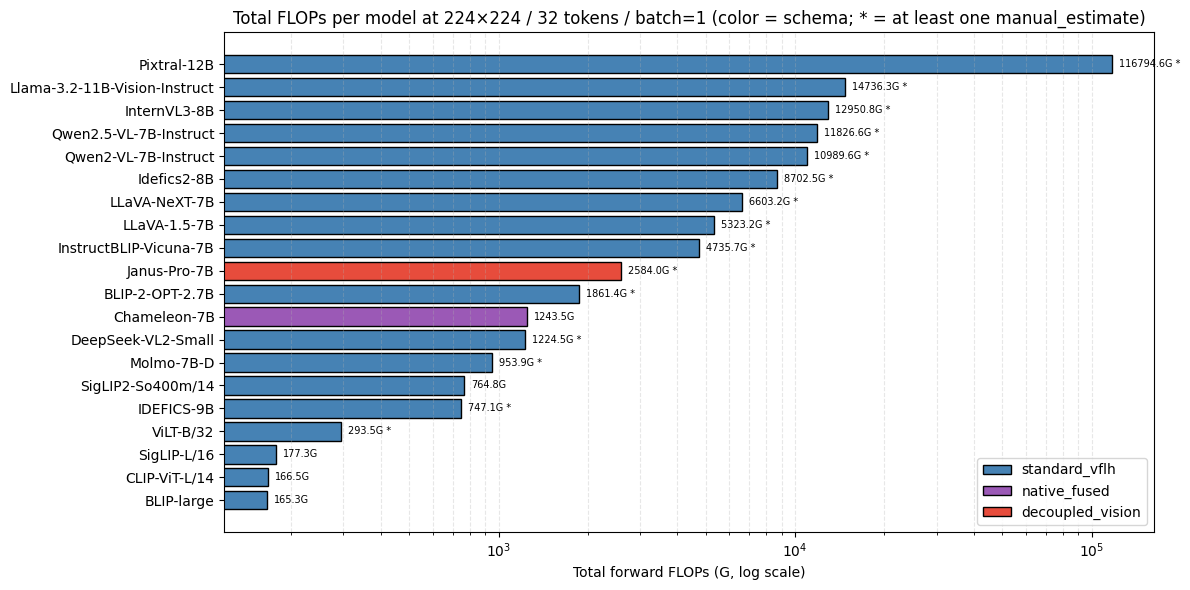

Saved to /workspace/code_active/outputs/figures/nb03_total_flops_bar.png


In [22]:
if results:
    plot_df = flops_df.copy().sort_values('total_G').reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(12, 6))
    schema_colors = {'standard_vflh': 'steelblue', 'native_fused': '#9B59B6', 'decoupled_vision': '#E74C3C'}
    bar_colors = [schema_colors.get(s, 'gray') for s in plot_df['schema']]
    # Clip lower so the log axis can render zero rows
    bars = ax.barh(plot_df['name'], plot_df['total_G'].clip(lower=0.01),
                   color=bar_colors, edgecolor='black')
    ax.set_xscale('log')
    ax.set_xlabel('Total forward FLOPs (G, log scale)')
    ax.set_title('Total FLOPs per model at 224×224 / 32 tokens / batch=1 (color = schema; * = at least one manual_estimate)')
    for bar, val, est in zip(bars, plot_df['total_G'], plot_df['any_estimate']):
        label = f'{val:.1f}G' + (' *' if est else '')
        ax.annotate(label, xy=(bar.get_width(), bar.get_y() + bar.get_height()/2),
                    xytext=(5, 0), textcoords='offset points', va='center', fontsize=7)
    from matplotlib.patches import Patch
    legend_handles = [Patch(facecolor=c, label=s, edgecolor='black') for s, c in schema_colors.items()]
    ax.legend(handles=legend_handles, loc='lower right')
    ax.grid(True, which='both', axis='x', linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIG_DIR / 'nb03_total_flops_bar.png', dpi=300, bbox_inches='tight')
    plt.show()
    print(f'Saved to {FIG_DIR / "nb03_total_flops_bar.png"}')

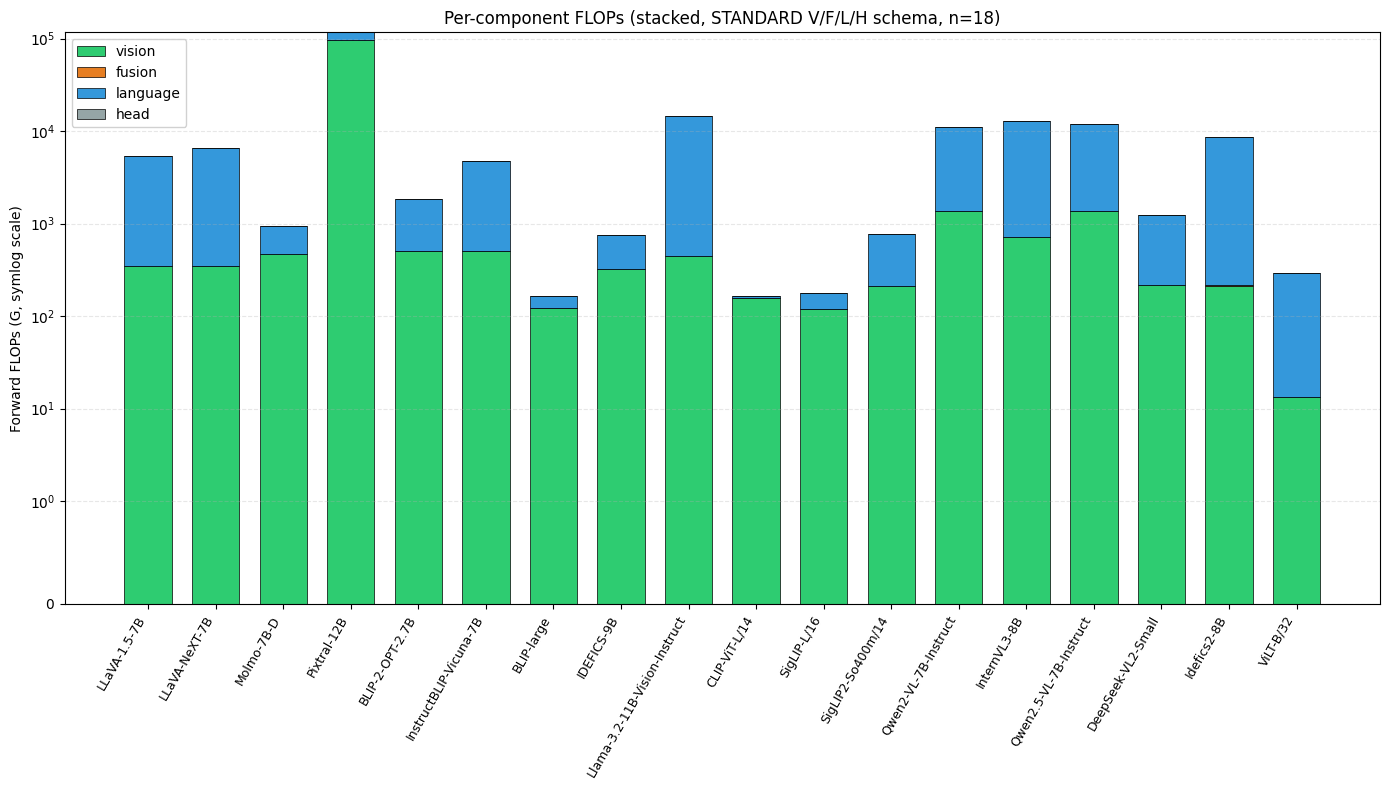

Saved to /workspace/code_active/outputs/figures/nb03_stacked_vflh_standard.png


In [23]:
if results:
    # Stacked V/F/L/H FLOPs for STANDARD-SCHEMA models
    sb_df = flops_df[flops_df['schema'] == 'standard_vflh'].copy().sort_values(['family', 'year', 'name']).reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(14, 8))
    x = np.arange(len(sb_df))
    width = 0.7
    colors = {'vision': '#2ECC71', 'fusion': '#E67E22', 'language': '#3498DB', 'head': '#95A5A6'}
    bottoms = np.zeros(len(sb_df))
    for cname in ['vision', 'fusion', 'language', 'head']:
        col = f'{cname}_flops_g'
        if col not in sb_df.columns:
            continue
        vals = sb_df[col].fillna(0).clip(lower=0).values
        ax.bar(x, vals, width=width, bottom=bottoms, color=colors[cname],
               edgecolor='black', linewidth=0.5, label=cname)
        bottoms += vals
    ax.set_xticks(x)
    ax.set_xticklabels(sb_df['name'], rotation=60, ha='right', fontsize=9)
    ax.set_ylabel('Forward FLOPs (G, symlog scale)')
    ax.set_yscale('symlog', linthresh=1.0)
    ax.set_title('Per-component FLOPs (stacked, STANDARD V/F/L/H schema, n={})'.format(len(sb_df)))
    ax.legend(loc='upper left', framealpha=0.9)
    ax.grid(True, axis='y', linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIG_DIR / 'nb03_stacked_vflh_standard.png', dpi=300, bbox_inches='tight')
    plt.show()
    print(f'Saved to {FIG_DIR / "nb03_stacked_vflh_standard.png"}')

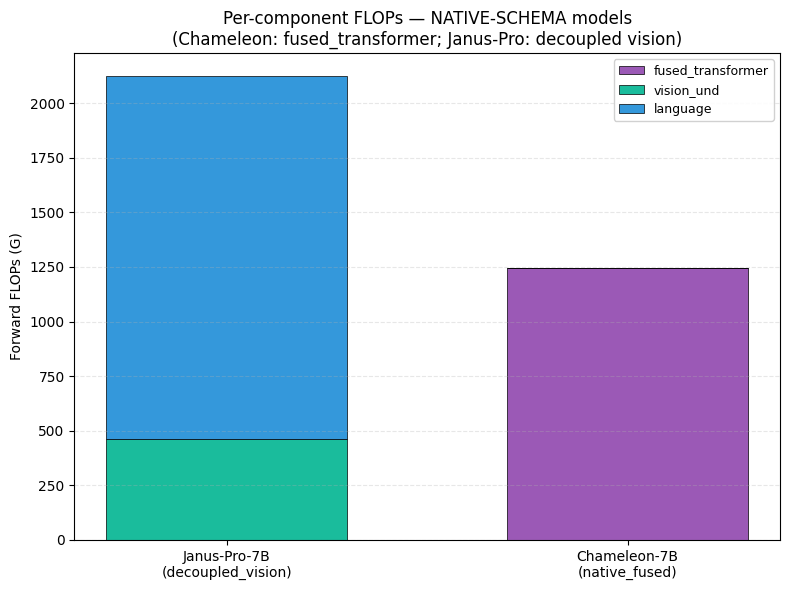

Saved to /workspace/code_active/outputs/figures/nb03_stacked_native.png


In [24]:
if results:
    # Stacked native-schema FLOPs (Chameleon + Janus)
    native_df = flops_df[flops_df['schema'].isin(['native_fused', 'decoupled_vision'])].copy().sort_values(['schema', 'name']).reset_index(drop=True)
    if len(native_df) == 0:
        print('No native-schema models in the result set.')
    else:
        fig, ax = plt.subplots(figsize=(8, 6))
        x = np.arange(len(native_df))
        width = 0.6
        native_palette = {
            'fused_transformer': '#9B59B6',  # Chameleon
            'vision_und':        '#1ABC9C',  # Janus understanding
            'vision_gen':        '#16A085',  # Janus generation
            'embeddings':        '#F39C12',
            'fusion':            '#E67E22',
            'language':          '#3498DB',
            'head':              '#95A5A6',
        }
        bottoms = np.zeros(len(native_df))
        for cname in ['fused_transformer', 'vision_und', 'vision_gen', 'embeddings', 'fusion', 'language', 'head']:
            col = f'{cname}_flops_g'
            if col not in native_df.columns:
                continue
            vals = native_df[col].fillna(0).clip(lower=0).values
            if vals.sum() == 0:
                continue
            ax.bar(x, vals, width=width, bottom=bottoms, color=native_palette.get(cname, 'gray'),
                   edgecolor='black', linewidth=0.5, label=cname)
            bottoms += vals
        ax.set_xticks(x)
        ax.set_xticklabels([f'{n}\n({s})' for n, s in zip(native_df['name'], native_df['schema'])], fontsize=10)
        ax.set_ylabel('Forward FLOPs (G)')
        ax.set_title('Per-component FLOPs — NATIVE-SCHEMA models\n(Chameleon: fused_transformer; Janus-Pro: decoupled vision)')
        ax.legend(loc='upper right', framealpha=0.9, fontsize=9)
        ax.grid(True, axis='y', linestyle='--', alpha=0.3)
        plt.tight_layout()
        plt.savefig(FIG_DIR / 'nb03_stacked_native.png', dpi=300, bbox_inches='tight')
        plt.show()
        print(f'Saved to {FIG_DIR / "nb03_stacked_native.png"}')

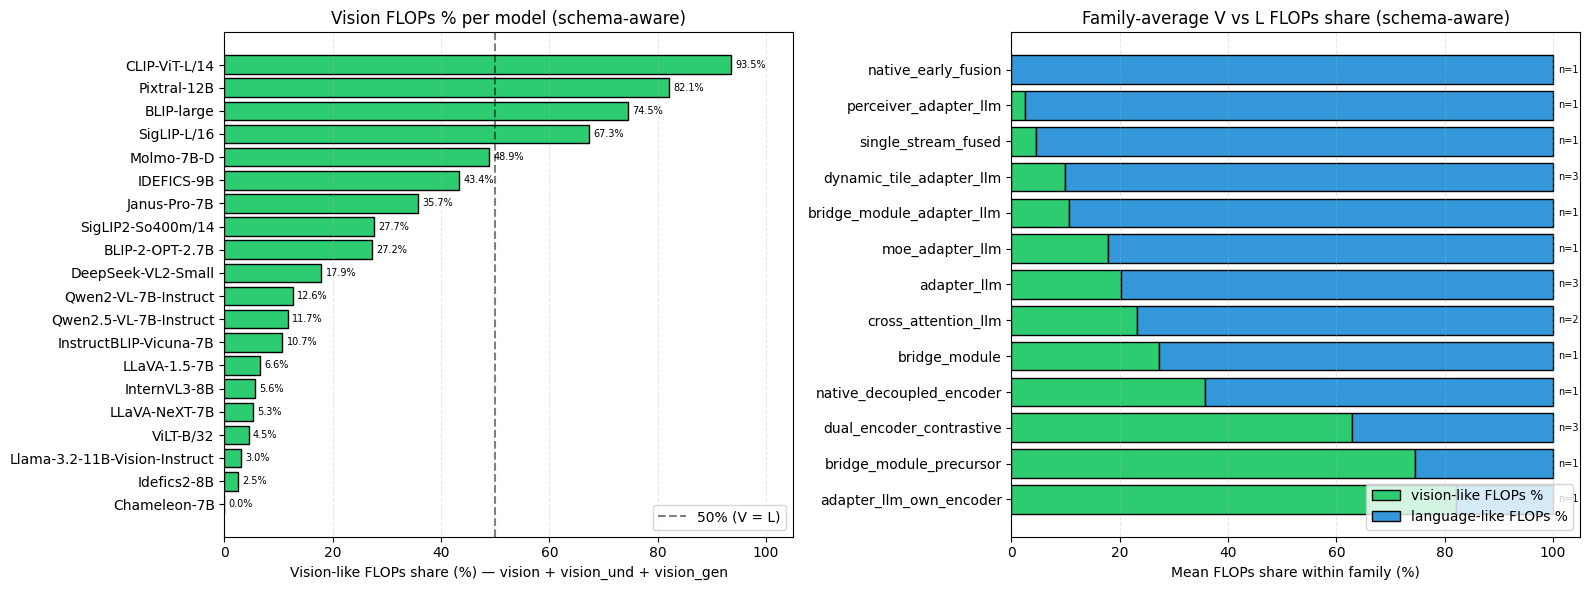

Saved to /workspace/code_active/outputs/figures/nb03_vision_flops_pct_and_family.png


In [25]:
if results:
    # Split panel: per-model vision FLOPs % + family-average
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    rdf = flops_df.sort_values('vision_flops_pct', ascending=True).copy()
    bars = axes[0].barh(rdf['name'], rdf['vision_flops_pct'], color='#2ECC71', edgecolor='black')
    axes[0].axvline(50, color='black', linestyle='--', alpha=0.5, label='50% (V = L)')
    axes[0].set_xlim(0, 105)
    axes[0].set_xlabel('Vision-like FLOPs share (%) — vision + vision_und + vision_gen')
    axes[0].set_title('Vision FLOPs % per model (schema-aware)')
    axes[0].legend()
    axes[0].grid(True, axis='x', linestyle='--', alpha=0.3)
    for bar, val in zip(bars, rdf['vision_flops_pct']):
        axes[0].annotate(f'{val:.1f}%', xy=(bar.get_width(), bar.get_y() + bar.get_height()/2),
                         xytext=(3, 0), textcoords='offset points', va='center', fontsize=7)

    # Right panel: family-average vision vs language FLOPs share
    fam_summary = flops_df.groupby('family').agg(
        n=('name', 'count'),
        avg_vision_flops_pct=('vision_flops_pct', 'mean'),
        avg_language_flops_pct=('language_flops_pct', 'mean'),
    ).sort_values('avg_vision_flops_pct', ascending=False)
    axes[1].barh(fam_summary.index, fam_summary['avg_vision_flops_pct'],
                 color='#2ECC71', edgecolor='black', label='vision-like FLOPs %')
    axes[1].barh(fam_summary.index, fam_summary['avg_language_flops_pct'],
                 left=fam_summary['avg_vision_flops_pct'],
                 color='#3498DB', edgecolor='black', label='language-like FLOPs %')
    axes[1].set_xlim(0, 105)
    axes[1].set_xlabel('Mean FLOPs share within family (%)')
    axes[1].set_title('Family-average V vs L FLOPs share (schema-aware)')
    axes[1].legend(loc='lower right')
    for i, (idx, row) in enumerate(fam_summary.iterrows()):
        axes[1].annotate(f'n={int(row["n"])}', xy=(101, i), va='center', fontsize=7)
    axes[1].grid(True, axis='x', linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIG_DIR / 'nb03_vision_flops_pct_and_family.png', dpi=300, bbox_inches='tight')
    plt.show()
    print(f'Saved to {FIG_DIR / "nb03_vision_flops_pct_and_family.png"}')

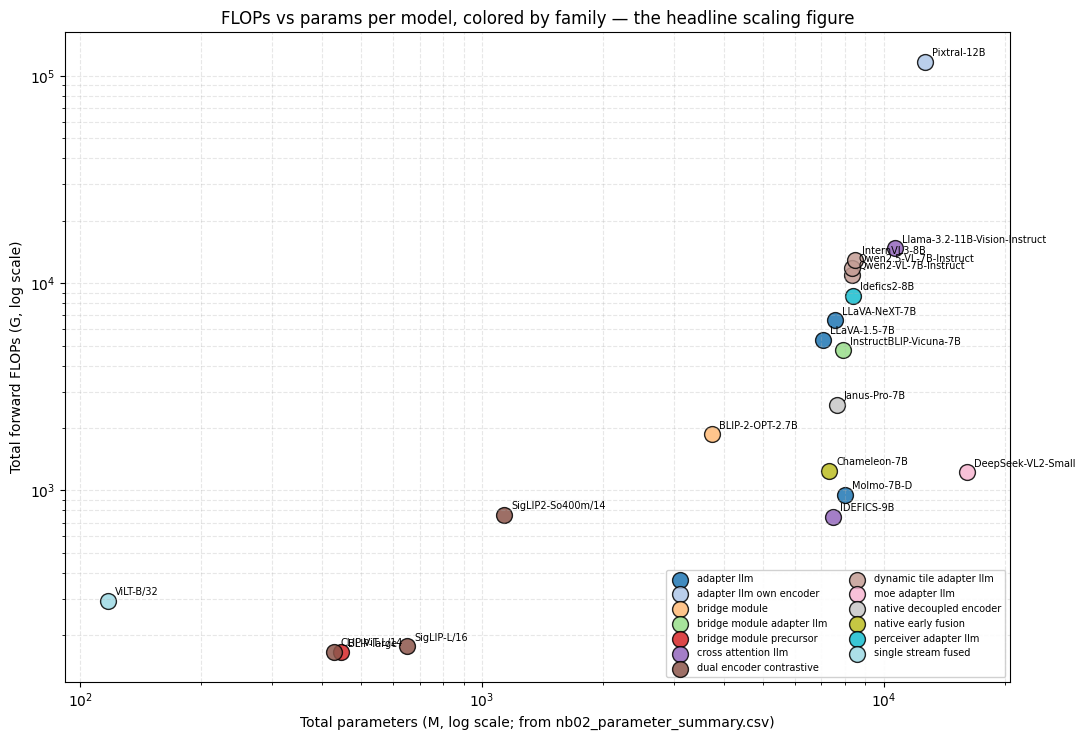

Saved to /workspace/code_active/outputs/figures/nb03_flops_vs_params.png


In [26]:
# FLOPs vs params scatter — read params from notebook 02's CSV if it exists
params_csv = MEASUREMENT_DIR / 'nb02_parameter_summary.csv'
if results and params_csv.exists():
    params_df = pd.read_csv(params_csv)
    merged = params_df.merge(
        flops_df[['name', 'total_G', 'any_estimate']],
        on='name', how='inner',
    )
    if len(merged) == 0:
        print('No overlap between params and FLOPs results — did notebook 02 produce nb02_parameter_summary.csv?')
    else:
        fig, ax = plt.subplots(figsize=(11, 7.5))
        families = sorted(merged['family'].unique())
        cmap = plt.get_cmap('tab20', max(len(families), 10))
        for i, fam in enumerate(families):
            d = merged[merged['family'] == fam]
            ax.scatter(
                d['total_M'], d['total_G'].clip(lower=0.1),
                s=130, color=cmap(i % cmap.N), edgecolor='black', alpha=0.85,
                label=fam.replace('_', ' '),
            )
            for _, row in d.iterrows():
                ax.annotate(
                    row['name'],
                    (row['total_M'], max(row['total_G'], 0.1)),
                    xytext=(5, 4), textcoords='offset points', fontsize=7,
                )
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlabel('Total parameters (M, log scale; from nb02_parameter_summary.csv)')
        ax.set_ylabel('Total forward FLOPs (G, log scale)')
        ax.set_title('FLOPs vs params per model, colored by family — the headline scaling figure')
        ax.legend(loc='lower right', fontsize=7, framealpha=0.9, ncol=2)
        ax.grid(True, which='both', linestyle='--', alpha=0.3)
        plt.tight_layout()
        plt.savefig(FIG_DIR / 'nb03_flops_vs_params.png', dpi=300, bbox_inches='tight')
        plt.show()
        print(f'Saved to {FIG_DIR / "nb03_flops_vs_params.png"}')
elif results:
    print(f'Skipping FLOPs-vs-params scatter — {params_csv.name} not found.')
    print('Run notebook 02 (02_parameter_analysis_v3.ipynb) first to populate the params CSV, then re-run this cell.')

---
## 11. Per-family FLOPs summary statistics

Aggregate FLOPs by family — this is one of the headline tables for the paper.

In [27]:
if results:
    family_summary = flops_df.groupby('family').agg(
        n_models=('name', 'count'),
        avg_total_G=('total_G', 'mean'),
        avg_vision_flops_pct=('vision_flops_pct', 'mean'),
        avg_fusion_flops_pct=('fusion_flops_pct', 'mean'),
        avg_language_flops_pct=('language_flops_pct', 'mean'),
        any_estimate_rate=('any_estimate', 'mean'),
        models=('name', lambda s: ', '.join(s)),
    ).round(2).sort_values('avg_vision_flops_pct', ascending=False)
family_summary if results else None

,n_models,avg_total_G,avg_vision_flops_pct,avg_fusion_flops_pct,avg_language_flops_pct,any_estimate_rate,models
family,,,,,,,
adapter_llm_own_encoder,1,116794.56,82.10,0.0,17.90,1.0,Pixtral-12B
bridge_module_precursor,1,165.30,74.50,0.0,25.50,0.0,BLIP-large
dual_encoder_contrastive,3,369.57,62.83,0.0,37.17,0.0,"CLIP-ViT-L/14, SigLIP-L/16, SigLIP2-So400m/14"
native_decoupled_encoder,1,2583.98,35.70,0.0,64.30,1.0,Janus-Pro-7B
bridge_module,1,1861.41,27.20,0.0,72.80,1.0,BLIP-2-OPT-2.7B
cross_attention_llm,2,7741.71,23.20,0.0,76.80,1.0,"IDEFICS-9B, Llama-3.2-11B-Vision-Instruct"
adapter_llm,3,4293.46,20.27,0.0,79.73,1.0,"LLaVA-1.5-7B, LLaVA-NeXT-7B, Molmo-7B-D"
moe_adapter_llm,1,1224.49,17.90,0.0,82.10,1.0,DeepSeek-VL2-Small
bridge_module_adapter_llm,1,4735.67,10.70,0.0,89.30,1.0,InstructBLIP-Vicuna-7B


In [28]:
# Cross-family interpretation
if results:
    print('=== Family-level FLOPs allocation patterns (schema-aware) ===\n')
    print('Vision-FLOPs-dominant families (mean vision % > 70%):')
    vd = family_summary[family_summary['avg_vision_flops_pct'] > 70]
    for fam, row in vd.iterrows():
        print(f'  {fam:35s} mean vision FLOPs = {row["avg_vision_flops_pct"]:.1f}%  (n={int(row["n_models"])})')
    print('\nLanguage-FLOPs-dominant families (mean language % > 70%):')
    ld = family_summary[family_summary['avg_language_flops_pct'] > 70]
    for fam, row in ld.iterrows():
        print(f'  {fam:35s} mean language FLOPs = {row["avg_language_flops_pct"]:.1f}%  (n={int(row["n_models"])})')
    print('\nMixed / native families (neither dominates, or schema undefined):')
    bal = family_summary[(family_summary['avg_vision_flops_pct'] <= 70) & (family_summary['avg_language_flops_pct'] <= 70)]
    for fam, row in bal.iterrows():
        print(f'  {fam:35s} V={row["avg_vision_flops_pct"]:.1f}%  L={row["avg_language_flops_pct"]:.1f}%  (n={int(row["n_models"])})')

=== Family-level FLOPs allocation patterns (schema-aware) ===

Vision-FLOPs-dominant families (mean vision % > 70%):
  adapter_llm_own_encoder             mean vision FLOPs = 82.1%  (n=1)
  bridge_module_precursor             mean vision FLOPs = 74.5%  (n=1)

Language-FLOPs-dominant families (mean language % > 70%):
  bridge_module                       mean language FLOPs = 72.8%  (n=1)
  cross_attention_llm                 mean language FLOPs = 76.8%  (n=2)
  adapter_llm                         mean language FLOPs = 79.7%  (n=3)
  moe_adapter_llm                     mean language FLOPs = 82.1%  (n=1)
  bridge_module_adapter_llm           mean language FLOPs = 89.3%  (n=1)
  dynamic_tile_adapter_llm            mean language FLOPs = 90.0%  (n=3)
  single_stream_fused                 mean language FLOPs = 95.5%  (n=1)
  perceiver_adapter_llm               mean language FLOPs = 97.5%  (n=1)
  native_early_fusion                 mean language FLOPs = 100.0%  (n=1)

Mixed / native families

---
## 12. Failures (debugging)

If any model failed, the row appears here. Look at `outputs/logs/<timestamp>_03_flops_analysis_nb__<model_id>.txt` for the full traceback.

In [29]:
if failures:
    failures_df = pd.DataFrame(failures)
    print(f'{len(failures)} failures:')
    failures_df
else:
    print('No failures — all models succeeded.')

No failures — all models succeeded.


---
## 13. Save FLOPs tables to disk

Per-model JSONs are already saved (incrementally merged by `run_full_audit`). Additionally save:
* `nb03_flops_summary.csv` — the wide master table.
* `nb03_flops_family_summary.csv` — the family-aggregated table.

In [30]:
if not results:
    print('Nothing to save — no successful results.')
else:
    csv_master = MEASUREMENT_DIR / 'nb03_flops_summary.csv'
    csv_family = MEASUREMENT_DIR / 'nb03_flops_family_summary.csv'
    flops_df.to_csv(csv_master, index=False)
    family_summary.to_csv(csv_family)
    print(f'Saved: {csv_master}')
    print(f'Saved: {csv_family}')
    print(f'Per-model JSONs (incrementally merged): {MEASUREMENT_DIR}/<hf_id>.json')
    print(f'Verbose .txt logs: {LOG_DIR}/*03_flops_analysis_nb*.txt')
    print(f'Figures: {FIG_DIR}/nb03_*.png')
    print()
    print(f'Models with per-model JSONs ({len(list(MEASUREMENT_DIR.glob("*.json")))} files):')
    for j in sorted(MEASUREMENT_DIR.glob('*.json')):
        print(f'  {j.name}')

Saved: /workspace/code_active/outputs/measurements/nb03_flops_summary.csv
Saved: /workspace/code_active/outputs/measurements/nb03_flops_family_summary.csv
Per-model JSONs (incrementally merged): /workspace/code_active/outputs/measurements/<hf_id>.json
Verbose .txt logs: /workspace/code_active/outputs/logs/*03_flops_analysis_nb*.txt
Figures: /workspace/code_active/outputs/figures/nb03_*.png

Models with per-model JSONs (20 files):
  HuggingFaceM4_idefics-9b.json
  HuggingFaceM4_idefics2-8b.json
  OpenGVLab_InternVL3-8B.json
  Qwen_Qwen2-VL-7B-Instruct.json
  Qwen_Qwen2.5-VL-7B-Instruct.json
  Salesforce_blip-image-captioning-large.json
  Salesforce_blip2-opt-2.7b.json
  Salesforce_instructblip-vicuna-7b.json
  allenai_Molmo-7B-D-0924.json
  dandelin_vilt-b32-finetuned-vqa.json
  deepseek-ai_Janus-Pro-7B.json
  deepseek-ai_deepseek-vl2-small.json
  facebook_chameleon-7b.json
  google_siglip-large-patch16-384.json
  google_siglip2-so400m-patch14-384.json
  llava-hf_llava-1.5-7b-hf.json
  

---
## Next steps

* If everything above looks right → continue to **`04_memory_analysis.ipynb`** (GPU required) for peak activation memory.
* If a model failed → open `outputs/logs/<timestamp>_03_flops_analysis_nb__<that_model>.txt`. Common causes:
  * Missing `HF_TOKEN` for gated models (LLaMA / IDEFICS / Pixtral / Llama-3.2-Vision)
  * `trust_remote_code` not allowed for InternVL3 / Molmo / DeepSeek-VL2 / Janus-Pro
  * `calflops` complains about a custom op → it should still fall through to fvcore / ptflops / manual_estimate; check the log for which counter actually fired
  * Pixtral-12B OOM (rare for FLOPs since calflops is analytical) → set `quantization='int8'` in the run loop
* If a row has `total_G = 0` — check the wide table in §8 to see which components were measured. The extractor may have returned `None` for the entire model.
* If `any_estimate = True` for more than a couple of rows — open §9 (source breakdown) and decide whether to mark those rows with an asterisk in the paper.
* If a number looks wrong compared to the model's published FLOPs (e.g. a Qwen-VL paper reports 5T but we report 200G) — remember our input config is the standardized 224×224 / 32 tokens, NOT the model's native resolution. Notebook 05 captures native-resolution token counts.
* Use `01_inspect_a_single_model.ipynb` to load the model interactively and walk the module tree if any component shows unexpected FLOPs.

*End of notebook 03 (verbose v2 — 2026-05-22). Schema-aware aggregation matches notebook 02 v3; F-2 fix verified inline on SigLIP-L.*